# Homework 9: Latent Diffusion and Stable Diffusion

SID4: 2046

Latent Diffusion Model on FashionMNIST using a pretrained VAE, latent space diffusion, conditional U Net denoising, classifier free guidance, and conditional sampling.

In [1]:
import os
import random
import json
import math
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

SEED = 2046

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Seed:", SEED)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Seed: 2046
Device: cuda
GPU: Tesla T4


In [2]:
!pip -q install diffusers transformers accelerate safetensors

## 1. VAE Compression and Latent Representation

FashionMNIST images are resized and converted to three channels for compatibility with the pretrained Stable Diffusion VAE. Images are encoded into the VAE latent space using the standard latent scaling factor of 0.18215. Reconstruction quality is evaluated using mean squared error.

In [3]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMAGE_SIZE = 128
BATCH_SIZE = 64

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

train_dataset = datasets.FashionMNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.FashionMNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

images, labels = next(iter(test_loader))

print("Train images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Batch shape:", images.shape)
print("Label shape:", labels.shape)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.16MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.73MB/s]


Train images: 60000
Test images: 10000
Batch shape: torch.Size([64, 3, 128, 128])
Label shape: torch.Size([64])


In [4]:
from diffusers import AutoencoderKL

VAE_MODEL = "stabilityai/sd-vae-ft-mse"
LATENT_SCALE = 0.18215

vae = AutoencoderKL.from_pretrained(
    VAE_MODEL,
    torch_dtype=torch.float32,
).to(device)

vae.eval()

for parameter in vae.parameters():
    parameter.requires_grad = False

print("VAE:", VAE_MODEL)
print("Latent scaling factor:", LATENT_SCALE)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

VAE: stabilityai/sd-vae-ft-mse
Latent scaling factor: 0.18215


In [5]:
images = images.to(device)

with torch.no_grad():
    posterior = vae.encode(images).latent_dist

    latents_unscaled = posterior.mean
    latents = latents_unscaled * LATENT_SCALE

print("Input shape:", tuple(images.shape))
print("Latent shape:", tuple(latents.shape))
print("Latent dtype:", latents.dtype)
print("Latent min:", latents.min().item())
print("Latent max:", latents.max().item())
print("Latent mean:", latents.mean().item())
print("Latent std:", latents.std().item())

Input shape: (64, 3, 128, 128)
Latent shape: (64, 4, 16, 16)
Latent dtype: torch.float32
Latent min: -3.454496145248413
Latent max: 4.495213031768799
Latent mean: -0.04999128356575966
Latent std: 1.2648751735687256


In [6]:
with torch.no_grad():
    reconstructed = vae.decode(
        latents / LATENT_SCALE
    ).sample

reconstruction_mse = torch.mean(
    (reconstructed - images) ** 2
).item()

print("Reconstructed shape:", tuple(reconstructed.shape))
print("Reconstruction MSE:", reconstruction_mse)

Reconstructed shape: (64, 3, 128, 128)
Reconstruction MSE: 0.0007419202011078596


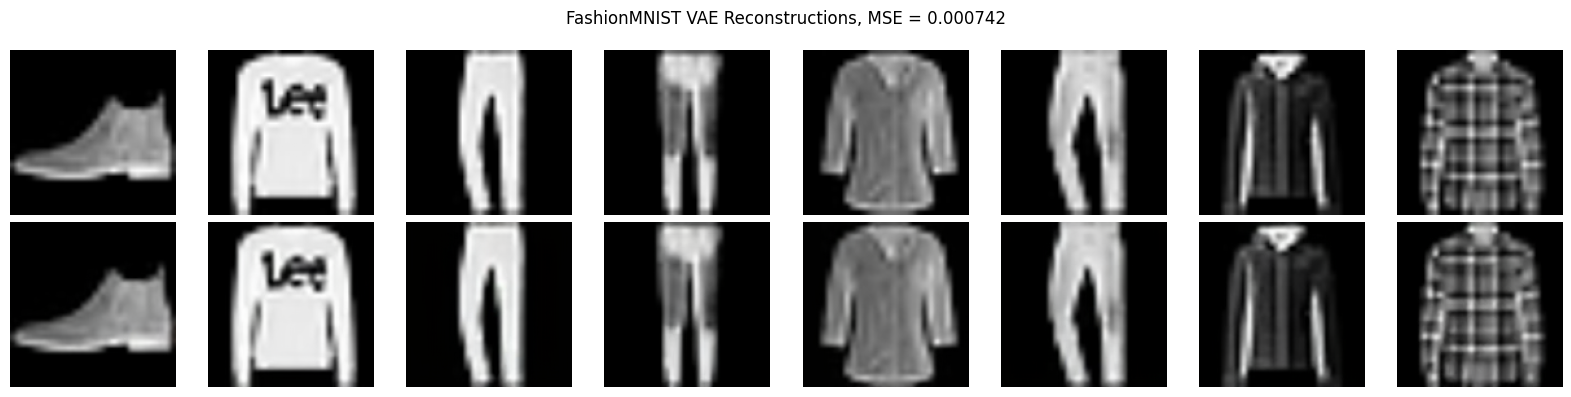

In [7]:
def to_display(x):
    return (
        x.detach()
        .cpu()
        .clamp(-1, 1)
        .add(1)
        .div(2)
    )

original_display = to_display(images)
reconstructed_display = to_display(reconstructed)

n_show = 8

fig, axes = plt.subplots(
    2,
    n_show,
    figsize=(16, 4)
)

for i in range(n_show):
    axes[0, i].imshow(
        original_display[i].permute(1, 2, 0)
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_display[i].permute(1, 2, 0)
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    fontsize=12
)

axes[1, 0].set_ylabel(
    "Reconstruction",
    fontsize=12
)

plt.suptitle(
    f"FashionMNIST VAE Reconstructions, MSE = {reconstruction_mse:.6f}"
)

plt.tight_layout()

plt.savefig(
    "/content/vae_reconstructions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [8]:
vae_metrics = {
    "vae_model": VAE_MODEL,
    "latent_scaling_factor": LATENT_SCALE,
    "input_shape": list(images.shape),
    "latent_shape": list(latents.shape),
    "reconstruction_mse": reconstruction_mse,
    "latent_mean": latents.mean().item(),
    "latent_std": latents.std().item(),
}

with open(
    "/content/vae_metrics.json",
    "w"
) as f:
    json.dump(
        vae_metrics,
        f,
        indent=2
    )

print(json.dumps(vae_metrics, indent=2))

{
  "vae_model": "stabilityai/sd-vae-ft-mse",
  "latent_scaling_factor": 0.18215,
  "input_shape": [
    64,
    3,
    128,
    128
  ],
  "latent_shape": [
    64,
    4,
    16,
    16
  ],
  "reconstruction_mse": 0.0007419202011078596,
  "latent_mean": -0.04999128356575966,
  "latent_std": 1.2648751735687256
}
